# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_: 
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: 
- _Student No._: 20XX-XXXXX
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report
![1](7plot.png)

# The plot shows the comparison of root estimates ($x_i$) across number of iterations ($i$) for the numerical techniques converging toward the root near $x \approx 4.5959$. Newton's and secant methods achieve rapid convergence in 6 to 12 steps, whereas fixed-point and bisection methods require 40 and 26 steps, respectively. Different initial guesses may lead to different convergence points since the guess at 4 converged to the other root near x = 2. This shows the sensitivity of Newton's method and the need for the user to know an accurate neighborhood of points where the root may be and know the derivative of the function. The secant method also offered a rapid quadratic convergence but is slower than Newton's method without needing the derivative beforehand. Bisection offered a slow but linear convergence that has a guaranteed chance of converging as long as the two initial guesses satisfy opposite signs. The slowest was the fix-point method overall, derivative-based and secant methods offer high speed at the cost of requiring analytical derivatives or dual guesses, while bisection and fixed-point provide simplicity at the expense of a slower convergence rate.

### Report figure

<img src="figures/cat.jpg" alt="Alt text" width=45%> <img src="figures/cat.jpg" alt="Alt text" width=45%>


EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=-5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

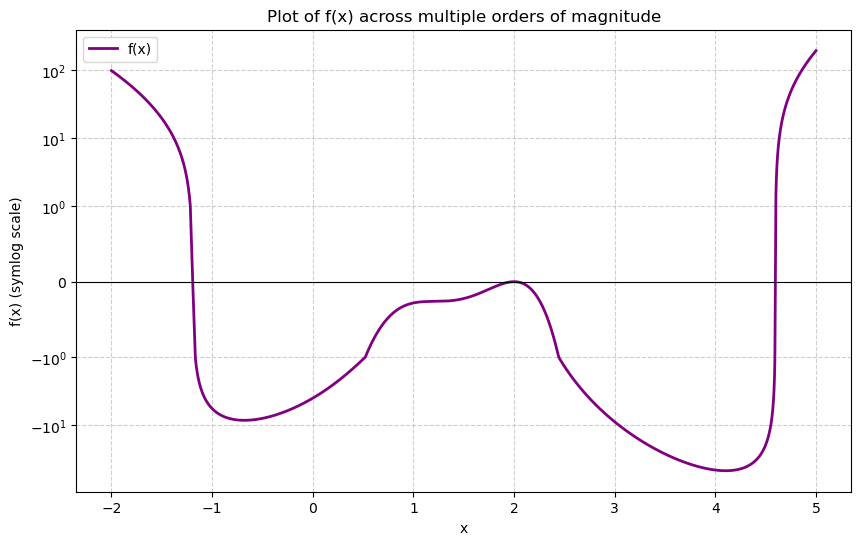

In [13]:

x = np.linspace(-2,5,100000)
func = -x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

plt.figure(figsize=(10, 6))
plt.plot(x, func, color='purple', linewidth=2, label='f(x)')


plt.yscale('symlog', linthresh=1.0)


plt.title('Plot of f(x) across multiple orders of magnitude')
plt.xlabel('x')
plt.ylabel('f(x) (symlog scale)')
plt.grid(True, which="both", linestyle='--', alpha=0.6)
plt.axhline(0, color='black', linewidth=0.8)
plt.legend()

plt.show()

In [31]:
import math

def fixedpoint(g, xold):
    for _ in range(100):
        xnew = g(xold)
        if abs(xnew - xold) < 1e-8: # Stop when guess stops changing
            return xnew
        xold = xnew
    else: 
        print("none")
    return xnew





def g1(x):
    return np.cbrt(np.exp(x) -2)


def g2(x):
    return np.log(x**3 + 2)


def g3(x):
    g_raw = -(-x**5 + 4*x**4 - 4*x**3 + x**2*math.exp(x) - 2*x**2 - 4*x*math.exp(x) + 4*math.exp(x) - 8) / 8
    return 0.5 * x + 0.5 * g_raw


# --- Find and Print All 3 Roots ---
r1 = fixedpoint(g1, xold=-2.0)
r2 = fixedpoint(g2, xold=4.0)
r3 = fixedpoint(g3, xold=2.5)

print(f"Root 1: {r1:.8f}")
print(f"Root 2: {r2:.8f}")
print(f"Root 3: {r3:.8f}")

# The algorithm rearranges the original polynomial into a form where g(x) = x and chooses a guess x where the derivative magnitude g'(x) < 1.
# The value at g(x_0) is taken then subtracted iterably until the difference between succeeding iterations is close to zero. That x-value is the root.
# The x-value where g(x) = x is true is also the x-value where f(x) = 0 is true, thus it is the root.

none
Root 1: -1.19268577
Root 2: 4.59586355
Root 3: 1.91462925


In [36]:
# Bisection
import numpy as np

def fun(x):
    return -x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def bisection(f, x0, x1, kmax=200, tol=1.e-8):
    f0 = f(x0)
    for k in range(1, kmax):
        x2 = (x0 + x1) / 2
        f2 = f(x2)
        if f0 * f2 < 0:
            x1 = x2
        else:
            x0, f0 = x2, f2
        x2new = (x0 + x1) / 2
        xdiff = abs(x2new - x2)
                
        if abs(xdiff / x2new) < tol:
            break
    else:
        x2new = None
    return x2new

# Print the final root for each interval
print("Root in [-2, 0]:", bisection(fun, -2, 0))

print("Root in [3, 5] :", bisection(fun, 3, 5))

# The root at 2 cannot be obtained since the neighborhood of x-values around it has no opposite-signed pairs.

# The algorithm finds a root by trapping it between two points of opposite signs and repeatedly cutting the interval in half. 
# At each step, it tests the midpoint, discards the half where the root isn't,
# and repeats until the interval shrinks to the desired tolerance.

Root in [-2, 0]: -1.1926857605576515
Root in [3, 5] : 4.595863550901413


In [53]:
# Newton's Method 
import numpy as np


x = np.linspace(-2,5,100000)
def fN(x):
    return -x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8
def dfN(x): # analytically solved derivative
    return -5*x**4 + 16*x**3 + x**2*np.exp(x) - 12*x**2 - 2*x*np.exp(x) - 4*x + 8


def newton(f, df, x0, tol=1e-8, iter=200):
    x = float(x0)
    for _ in range(iter):
        fx = fN(x)
        dfx = dfN(x)
        if abs(fx/dfx) < tol:
            return x
        
        if dfx == 0:
            break
        x = x - fx / dfx
    return x


print("Root 1:", newton(fN, dfN, -1.0))  # -1.19268576...
print("Root 2:", newton(fN, dfN, 1.5))   #  2.00000000...
print("Root 3:", newton(fN, dfN, 5.0))   #  4.59586356...

# For Newton's method, the derivative is explicitly taken and used for finding the root. The formula for Newton's method
# involves recurringly taking the x-intercept of the equation of the tangent line of the function, starting with an initial guess of x, which ideally
# is near the actual root. The tangent line slope is taken by using the derivative of the function. If the slope is negative, the algorithmn subtracts
# it to the previous guess of x and shifts it to the right. If its positive, it shifts the guess to the left, eventually leading to the actual root.

Root 1: -1.1926857650226055
Root 2: 2.0000000154586135
Root 3: 4.595863565002108


In [51]:
# secant method
import numpy as np

# Define the function
def fN(x):
    return -x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def secant(f, x0, x1, tol=1e-8, max_iter=200):
    x_prev = float(x0)
    x_curr = float(x1)
    
    for _ in range(max_iter):
        f_prev = f(x_prev)
        f_curr = f(x_curr)
        
        # Check convergence
        if abs(f_curr) < tol or abs(x_curr - x_prev) < tol:
            return x_curr
            
        denominator = f_curr - f_prev
        if denominator == 0:
            raise ValueError("Secant method failed: denominator is zero.")
            
        # Secant update formula
        x_next = x_curr - f_curr * (x_curr - x_prev) / denominator
        
        # Shift points for the next iteration
        x_prev = x_curr
        x_curr = x_next
        
    return x_curr

# Test with two initial guesses for each root
print("Root 1:", secant(fN, -1.0, -1.5))  # Around -1.19268576...
print("Root 2:", secant(fN, 1.5, 1.8))   # Around  2.00000000...
print("Root 3:", secant(fN, 4.0, 5.0))   # Around  4.59586356...

# instead of taking the derivative, the secant line of the function at that specific point is taken instead. For the most part, 
# the secant method is identical to Newton's method, but instead of taking the derivative value at that specific x value,
# the value of the secant line is taken at that x value.

Root 1: -1.1926857650225977
Root 2: 1.9999568283049354
Root 3: 4.5958635649223725


Fixed-Point Iterations: 40
Bisection Iterations:   26
Newton's ($x_0 = 5.0$) Iterations: 6
Newton's ($x_0 = 4.0$) Iterations: 23
Secant Iterations:      12


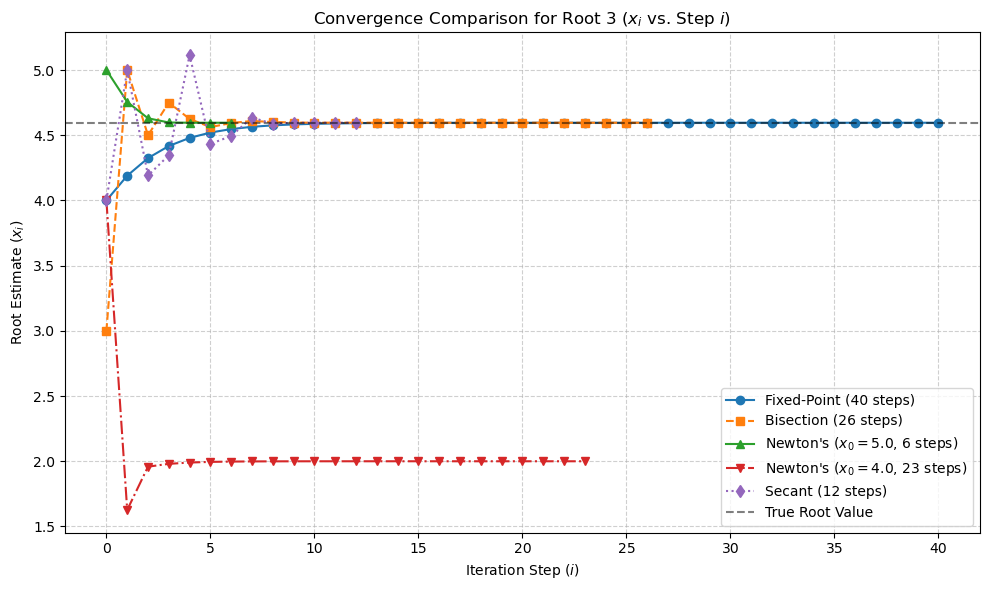

In [60]:
# 7

def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    return -5*x**4 + 16*x**3 + x**2*np.exp(x) - 12*x**2 - 2*x*np.exp(x) - 4*x + 8

# --- 1. Fixed-Point Method (Tracking History) ---
def fixed_point_history(g, x0, tol=1e-8, max_iter=200):
    history = [float(x0)]
    x = float(x0)
    for _ in range(max_iter):
        x_next = g(x)
        history.append(x_next)
        if abs(x_next - x) < tol:
            break
        x = x_next
    return history

# --- 2. Bisection Method (Tracking History) ---
def bisection_history(f, x0, x1, tol=1e-8, max_iter=200):
    history = [float(x0), float(x1)]
    f0 = f(x0)
    for _ in range(max_iter):
        x2 = (x0 + x1) / 2
        f2 = f(x2)
        if f0 * f2 < 0:
            x1 = x2
        else:
            x0, f0 = x2, f2
        x_new = (x0 + x1) / 2
        history.append(x_new)
        if abs(x_new - x2) / abs(x_new) < tol:
            break
    return history

# --- 3. Newton's Method (Tracking History) ---
def newton_history(f, df, x0, tol=1e-8, max_iter=200):
    history = [float(x0)]
    x = float(x0)
    for _ in range(max_iter):
        fx = f(x)
        dfx = df(x)
        if dfx == 0:
            break
        x_next = x - fx / dfx
        history.append(x_next)
        if abs(x_next - x) < tol or abs(fx / dfx) < tol:
            break
        x = x_next
    return history

# --- 4. Secant Method (Tracking History) ---
def secant_history(f, x0, x1, tol=1e-8, max_iter=200):
    history = [float(x0), float(x1)]
    x_prev, x_curr = float(x0), float(x1)
    for _ in range(max_iter):
        f_prev, f_curr = f(x_prev), f(x_curr)
        denominator = f_curr - f_prev
        if denominator == 0:
            break
        x_next = x_curr - f_curr * (x_curr - x_prev) / denominator
        history.append(x_next)
        if abs(x_next - x_curr) < tol or abs(f_curr) < tol:
            break
        x_prev, x_curr = x_curr, x_next
    return history

# --- Generate Convergence Data for Root 3 (approx 4.59586356) ---
g3 = lambda x: np.log(x**3 + 2)
h_fp = fixed_point_history(g3, x0=4.0)
h_bi = bisection_history(f, x0=3.0, x1=5.0)
h_ne1 = newton_history(f, df, x0=5.0)
h_ne2 = newton_history(f, df, x0=4.0)
h_se = secant_history(f, x0=4.0, x1=5.0)

# --- Print Number of Iterations ---
print(f"Fixed-Point Iterations: {len(h_fp) - 1}")
print(f"Bisection Iterations:   {len(h_bi) - 1}")
print(f"Newton's ($x_0 = 5.0$) Iterations: {len(h_ne1) - 1}")
print(f"Newton's ($x_0 = 4.0$) Iterations: {len(h_ne2) - 1}")
print(f"Secant Iterations:      {len(h_se) - 1}")

# --- Plotting the Convergence Curves ($x_i$ vs $i$) ---
plt.figure(figsize=(10, 6))

plt.plot(range(len(h_fp)), h_fp, marker='o', linestyle='-', label=f'Fixed-Point ({len(h_fp)-1} steps)')
plt.plot(range(len(h_bi)), h_bi, marker='s', linestyle='--', label=f'Bisection ({len(h_bi)-1} steps)')
plt.plot(range(len(h_ne1)), h_ne1, marker='^', linestyle='-', label=f"Newton's ($x_0 = 5.0$, {len(h_ne1)-1} steps)")
plt.plot(range(len(h_ne2)), h_ne2, marker='v', linestyle='-.', label=f"Newton's ($x_0 = 4.0$, {len(h_ne2)-1} steps)")
plt.plot(range(len(h_se)), h_se, marker='d', linestyle=':', label=f'Secant ({len(h_se)-1} steps)')

# True root reference line for Root 3
true_root_3 = 4.5958635649223725
plt.axhline(true_root_3, color='black', linestyle='--', alpha=0.5, label='True Root Value')

plt.title('Convergence Comparison for Root 3 ($x_i$ vs. Step $i$)', fontsize=12)
plt.xlabel('Iteration Step ($i$)', fontsize=10)
plt.ylabel('Root Estimate ($x_i$)', fontsize=10)
plt.grid(True, which='both', linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.savefig('7plot.png', dpi=150, bbox_inches='tight')
plt.show()

# run each method with guesses near the root of 4.5959 then graph it with respect to the number of iterations.

#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---